<a href="https://colab.research.google.com/github/omarsalahh223/machine_learning_project1.ipynb/blob/main/SVM_Hard_Soft_Kernel_Ionosphere.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/ionosphere.csv", header=None)

# last column is the label ('g' = good, 'b' = bad)
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = (df.iloc[:, -1].to_numpy() == "g").astype(int)      # 1 = good, 0 = bad
CLASS_NAMES = ["bad (b)", "good (g)"]

print(f"\nFeature matrix : {X.shape[0]} samples x {X.shape[1]} features")
print(f"Class balance  : good = {(y == 1).sum()}  |  bad = {(y == 0).sum()}")
print(f"Missing values : {np.isnan(X).sum()}")
df.head()


Feature matrix : 351 samples x 34 features
Class balance  : good = 225  |  bad = 126
Missing values : 0


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


In [ ]:
# Xs = StandardScaler().fit_transform(X)
y_pm = np.where(y == 1, 1, -1)                  # labels as -1 / +1
n, d = X.shape

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

scaler  = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test  = scaler.transform(X_test)

cross_val_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Train: {X_train.shape[0]} samples   Test: {X_test.shape[0]} samples")

Train: 245 samples   Test: 106 samples


In [ ]:
hard_svm = SVC(kernel="linear", C=1e6, max_iter=200_000)

hard_svm.fit(X_train, y_train)

y_pred    = hard_svm.predict(X_test)


train_acc = accuracy_score(y_train, hard_svm.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)
cm        = confusion_matrix(y_test, y_pred)

print(f"Training accuracy : {train_acc:.4f}")
print(f"Test accuracy     : {test_acc:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted)")
print(pd.DataFrame(cm, index=[f"actual {c}" for c in CLASS_NAMES], columns=[f"pred {c}"  for c in CLASS_NAMES]).to_string())

tn, fp, fn, tp = cm.ravel()
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("\nClassification report")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Training accuracy : 0.8980
Test accuracy     : 0.8962

Confusion matrix (rows = actual, columns = predicted)
                 pred bad (b)  pred good (g)
actual bad (b)             30              8
actual good (g)             3             65

TN=30  FP=8  FN=3  TP=65

Classification report
              precision    recall  f1-score   support

     bad (b)      0.909     0.789     0.845        38
    good (g)      0.890     0.956     0.922        68

    accuracy                          0.896       106
   macro avg      0.900     0.873     0.884       106
weighted avg      0.897     0.896     0.894       106



/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [ ]:
soft_grid = GridSearchCV(
    SVC(kernel="linear"),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cross_val_folds, scoring="accuracy", n_jobs=-1)

soft_grid.fit(X_train, y_train)
print(f"Best C           : {soft_grid.best_params_['C']}")
print(f"Best CV accuracy : {soft_grid.best_score_:.4f}\n")

soft_svm = SVC(kernel="linear", **soft_grid.best_params_)

soft_svm.fit(X_train, y_train)

y_pred    = soft_svm.predict(X_test)


train_acc = accuracy_score(y_train, soft_svm.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)
cm        = confusion_matrix(y_test, y_pred)

print(f"Training accuracy : {train_acc:.4f}")
print(f"Test accuracy     : {test_acc:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted)")
print(pd.DataFrame(cm, index=[f"actual {c}" for c in CLASS_NAMES], columns=[f"pred {c}"  for c in CLASS_NAMES]).to_string())

tn, fp, fn, tp = cm.ravel()
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("\nClassification report")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Best C           : 1
Best CV accuracy : 0.8735

Training accuracy : 0.9551
Test accuracy     : 0.8774

Confusion matrix (rows = actual, columns = predicted)
                 pred bad (b)  pred good (g)
actual bad (b)             29              9
actual good (g)             4             64

TN=29  FP=9  FN=4  TP=64

Classification report
              precision    recall  f1-score   support

     bad (b)      0.879     0.763     0.817        38
    good (g)      0.877     0.941     0.908        68

    accuracy                          0.877       106
   macro avg      0.878     0.852     0.862       106
weighted avg      0.877     0.877     0.875       106



In [ ]:
rbf_grid = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid={"C": [0.1, 1, 10, 100, 1000],
                "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1, "scale"]},
    cv=cross_val_folds, scoring="accuracy", n_jobs=-1)

rbf_grid.fit(X_train, y_train)
print(f"Best parameters  : {rbf_grid.best_params_}")
print(f"Best CV accuracy : {rbf_grid.best_score_:.4f}\n")

rbf_svm = SVC(kernel="rbf", **rbf_grid.best_params_)

rbf_svm.fit(X_train, y_train)

y_pred    = rbf_svm.predict(X_test)

train_acc = accuracy_score(y_train, rbf_svm.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)
cm        = confusion_matrix(y_test, y_pred)

print(f"Training accuracy : {train_acc:.4f}")
print(f"Test accuracy     : {test_acc:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted)")
print(pd.DataFrame(cm, index=[f"actual {c}" for c in CLASS_NAMES], columns=[f"pred {c}"  for c in CLASS_NAMES]).to_string())

tn, fp, fn, tp = cm.ravel()
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("\nClassification report")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Best parameters  : {'C': 1, 'gamma': 0.1}
Best CV accuracy : 0.9510

Training accuracy : 0.9878
Test accuracy     : 0.9245

Confusion matrix (rows = actual, columns = predicted)
                 pred bad (b)  pred good (g)
actual bad (b)             33              5
actual good (g)             3             65

TN=33  FP=5  FN=3  TP=65

Classification report
              precision    recall  f1-score   support

     bad (b)      0.917     0.868     0.892        38
    good (g)      0.929     0.956     0.942        68

    accuracy                          0.925       106
   macro avg      0.923     0.912     0.917       106
weighted avg      0.924     0.925     0.924       106



In [ ]:
other_kernels = {
    "poly (d=2)": SVC(kernel="poly", degree=2, C=1, gamma="scale"),
    "poly (d=3)": SVC(kernel="poly", degree=3, C=1, gamma="scale"),
    "sigmoid":    SVC(kernel="sigmoid", C=1, gamma="scale"),
}
for name, m in other_kernels.items():
    m.fit(X_train, y_train)
    print(f"{name:12s} test accuracy = {m.score(X_test, y_test):.4f}")

poly (d=2)   test accuracy = 0.8302
poly (d=3)   test accuracy = 0.7170
sigmoid      test accuracy = 0.9245


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [1] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


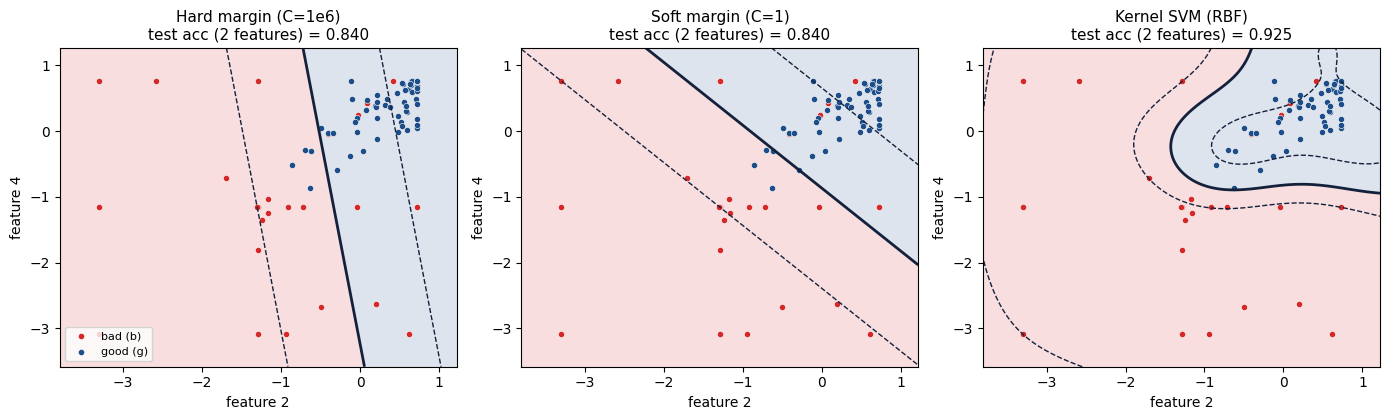

In [ ]:
X_scaled = StandardScaler().fit_transform(X)
selector = SelectKBest(f_classif, k=2).fit(X_scaled, y)
feat_idx = np.where(selector.get_support())[0]
X2 = selector.transform(X_scaled)

X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.30, random_state=42, stratify=y)

viz = {
    "Hard margin (C=1e6)": SVC(kernel="linear", C=1e6, max_iter=200_000),
    f"Soft margin (C={soft_grid.best_params_['C']})": SVC(kernel="linear", **soft_grid.best_params_),
    "Kernel SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
}

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 400),
                     np.linspace(X2[:, 1].min() - .5, X2[:, 1].max() + .5, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (name, m) in zip(axes, viz.items()):
    m.fit(X2_tr, y2_tr)
    Z = m.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-1e9, 0, 1e9], colors=["#D62828", "#1D4E89"], alpha=0.15)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="#14213D",
                linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    for cls, color in [(0, "#D62828"), (1, "#1D4E89")]:
        ax.scatter(X2_te[y2_te == cls, 0], X2_te[y2_te == cls, 1], s=20, c=color,
                    edgecolors="white", linewidths=0.4, label=CLASS_NAMES[cls])
    ax.set_title(f"{name}\ntest acc (2 features) = {m.score(X2_te, y2_te):.3f}", fontsize=11)
    ax.set_xlabel(f"feature {feat_idx[0]}"); ax.set_ylabel(f"feature {feat_idx[1]}")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()